# Introduction




# Prepare for analysis

## Load packages

In [1]:
import sys

sys.path.append("..")

In [2]:
from pathlib import Path

import yaml

from titanic.data import (
    combine_train_test,
    data_summary,
    frequent_data_summary,
    load_data,
    missing_data_summary,
    plot_count_pair,
    plot_distribution_pair,
    unique_data_summary,
)

In [3]:
PROJECT_ROOT = Path.cwd().parent
config = yaml.safe_load((PROJECT_ROOT / "configs" / "configs.yaml").read_text())

DATA_DIR = PROJECT_ROOT / config["data"]["data_dir"]
TRAIN_PATH = DATA_DIR / config["data"]["train_file"]
TEST_PATH = DATA_DIR / config["data"]["test_file"]

## Read the data

In [4]:
train_df, test_df = load_data(TRAIN_PATH, TEST_PATH)

## Quick glimpse of the data
TODO: Think if you can abstract away much here.

In [5]:
# train dataset summary
print("=== Train dataset summary ===")
data_summary(train_df)

=== Train dataset summary ===
Data shape: (891, 12))

--- Head ---
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123

In [6]:
# test dataset summary
print("=== Test dataset summary ===")
data_summary(test_df)

=== Test dataset summary ===
Data shape: (418, 11))

--- Head ---
   PassengerId  Pclass                                          Name     Sex  \
0          892       3                              Kelly, Mr. James    male   
1          893       3              Wilkes, Mrs. James (Ellen Needs)  female   
2          894       2                     Myles, Mr. Thomas Francis    male   
3          895       3                              Wirz, Mr. Albert    male   
4          896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female   

    Age  SibSp  Parch   Ticket     Fare Cabin Embarked  
0  34.5      0      0   330911   7.8292   NaN        Q  
1  47.0      1      0   363272   7.0000   NaN        S  
2  62.0      0      0   240276   9.6875   NaN        Q  
3  27.0      0      0   315154   8.6625   NaN        S  
4  22.0      1      1  3101298  12.2875   NaN        S  

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 # 

## Few statistics on the data

### Missing data

In [7]:
df_missing_train = missing_data_summary(train_df)
df_missing_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,0,177,0,0,0,0,687,2
Percent,0.0,0.0,0.0,0.0,0.0,19.86532,0.0,0.0,0.0,0.0,77.104377,0.224467
Types,int64,int64,int64,str,str,float64,int64,int64,str,float64,str,str


In [8]:
df_missing_test = missing_data_summary(test_df)
df_missing_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,0,0,0,0,86,0,0,0,1,327,0
Percent,0.0,0.0,0.0,0.0,20.574163,0.0,0.0,0.0,0.239234,78.229665,0.0
Types,int64,int64,str,str,float64,int64,int64,str,float64,str,str


### Most frequent data

In [9]:
df_frequent_train = frequent_data_summary(train_df)
df_frequent_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Most frequent item,1,0,3,"Braund, Mr. Owen Harris",male,24.0,0,0,347082,8.05,G6,S
Frequence,1,549,491,1,577,30,608,678,7,43,4,644
Percent from total,0.112,61.616,55.107,0.112,64.759,4.202,68.238,76.094,0.786,4.826,1.961,72.441


In [10]:
df_frequent_test = frequent_data_summary(test_df)
df_frequent_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Most frequent item,892,3,"Kelly, Mr. James",male,21.0,0,0,PC 17608,7.75,B57 B59 B63 B66,S
Frequence,1,218,1,266,17,283,324,5,21,3,270
Percent from total,0.239,52.153,0.239,63.636,5.12,67.703,77.512,1.196,5.036,3.297,64.593


### Unique values

In [11]:
df_unique_train = unique_data_summary(train_df)
df_unique_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,891,891,891,891,891,714,891,891,891,891,204,889
Uniques,891,2,3,891,2,88,7,7,681,248,147,3


In [12]:
df_unique_test = unique_data_summary(test_df)
df_unique_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Total,418,418,418,418,332,418,418,418,417,91,418
Uniques,418,3,418,2,79,7,8,363,169,76,3


# Exploratory data analysis

## Univariate analysis for all features


We show here two graphs in paralel:
* distribution of class values, split per Survived value
* comparison of class values, in train and test data


Let's first aggregate train and test data into one single dataframe, `all_df`.

In [13]:
all_df = combine_train_test(train_df, test_df)

In [14]:
all_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,set
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,train
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,train
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,train
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,train
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,train


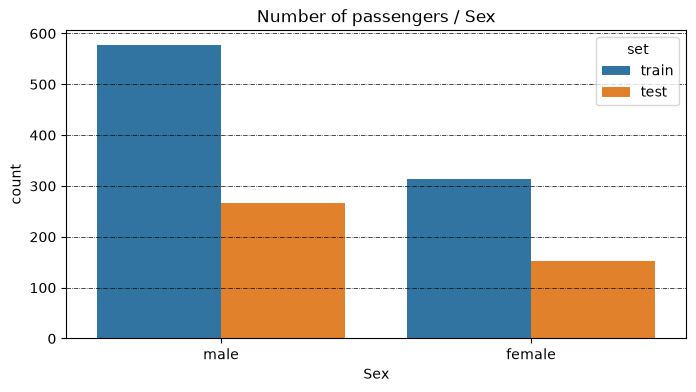

In [15]:
# Plot count pairs "Sex"
plot_count_pair(all_df, "Sex", "set")

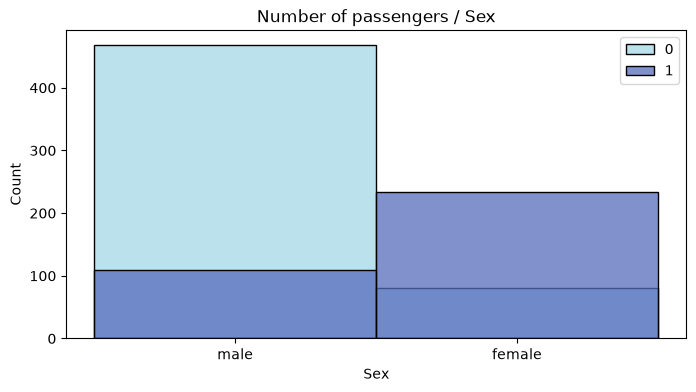

In [16]:
# Plot distribution pairs for "Sex" and hue as "Survived"
plot_distribution_pair(train_df, "Sex", "Survived")

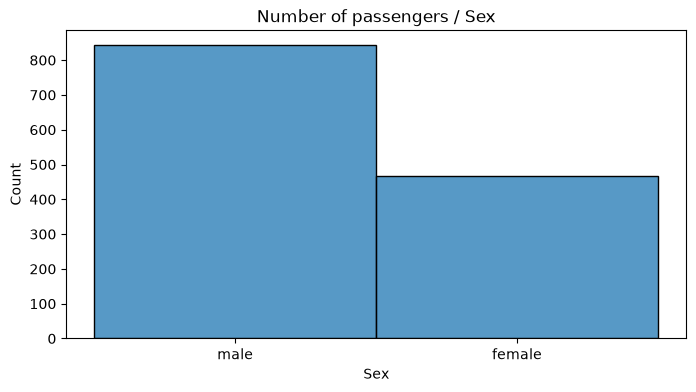

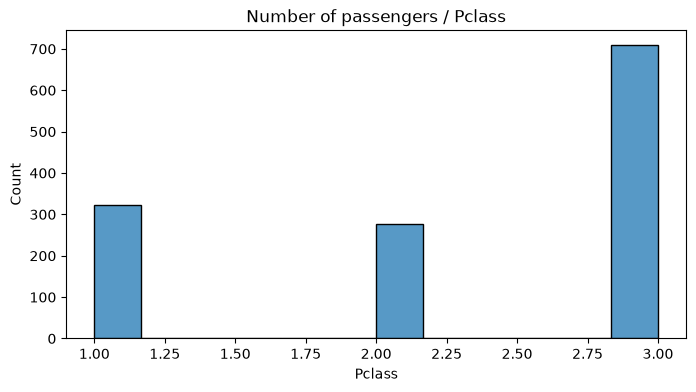

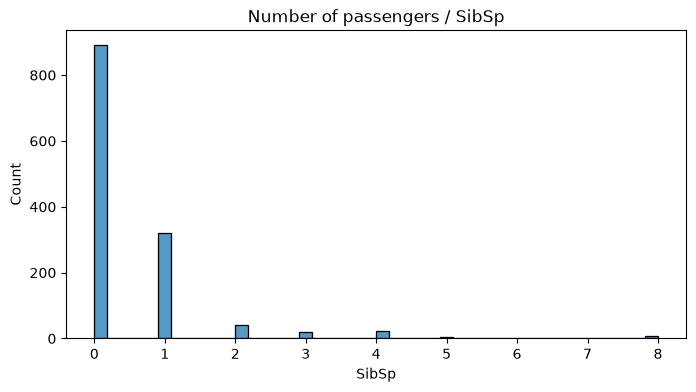

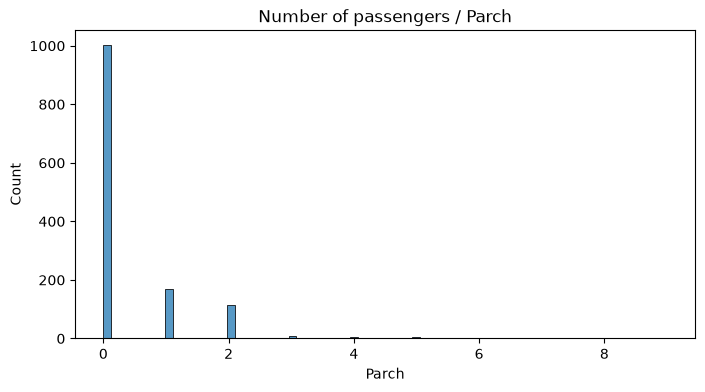

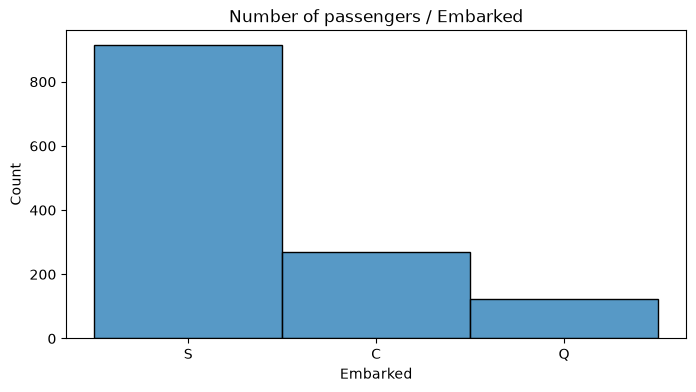

In [17]:
# Plot count pairs using all_df for the columns: Sex, Pclasss, SibSp, Parch, Embarked
for col in ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]:
    plot_distribution_pair(all_df, col)

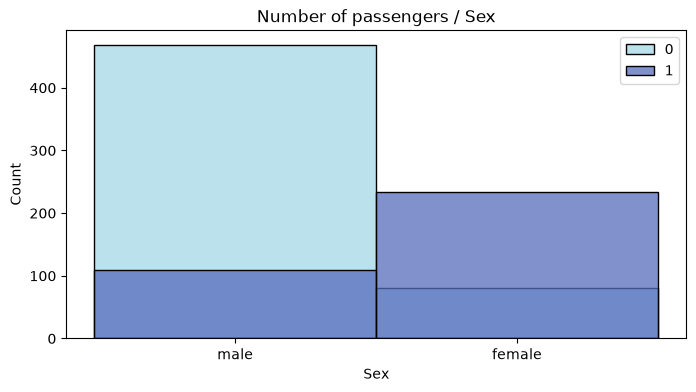

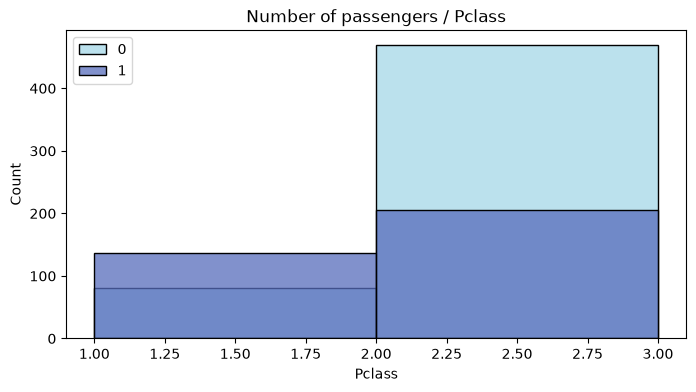

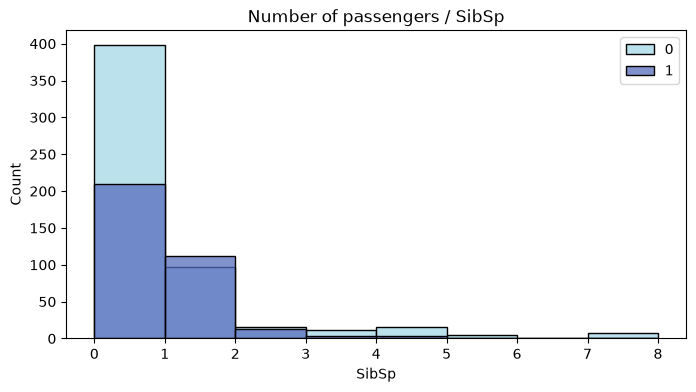

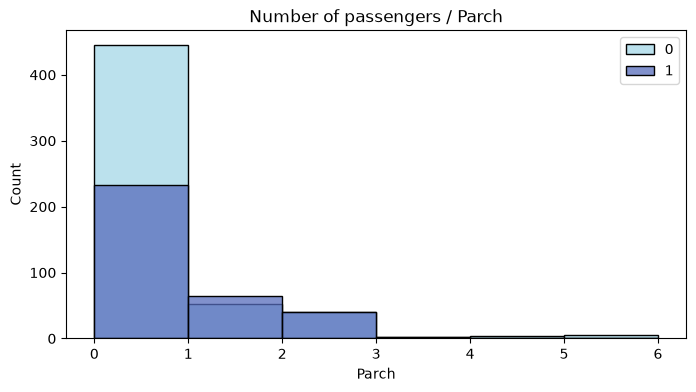

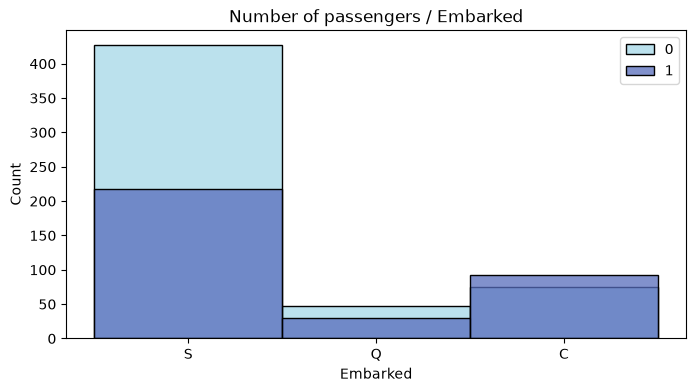

In [18]:
# Plot count pairs using all_df for the columns: Sex, Pclasss, SibSp, Parch, Embarked and use "Survived" as hue.
for col in ["Sex", "Pclass", "SibSp", "Parch", "Embarked"]:
    plot_distribution_pair(train_df, col, "Survived")

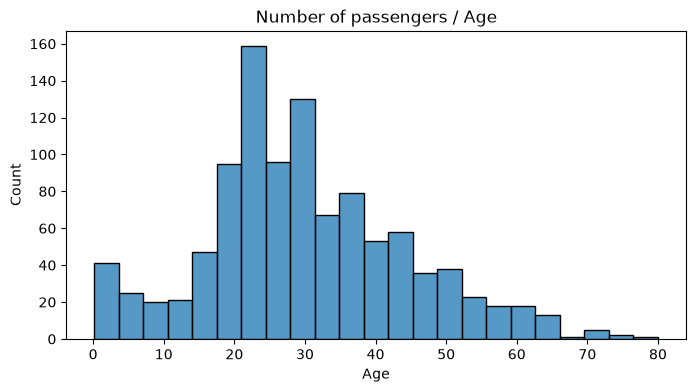

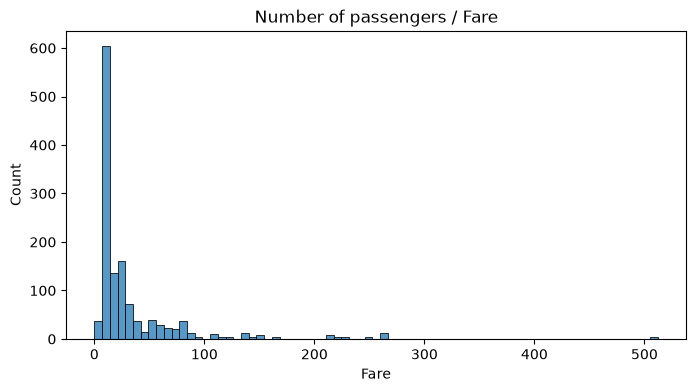

In [19]:
# Plot distribution pairs for Age and Fare
for col in ["Age", "Fare"]:
    plot_distribution_pair(all_df, col)

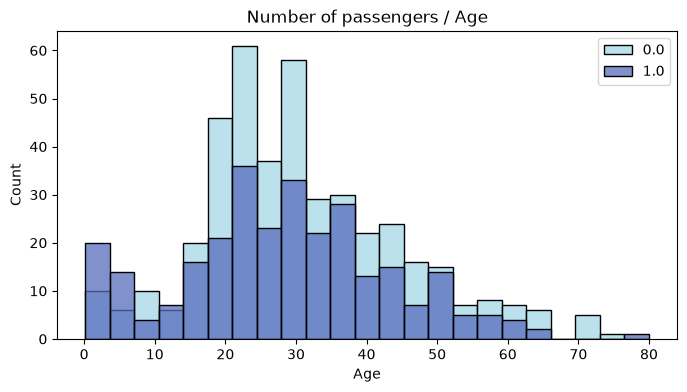

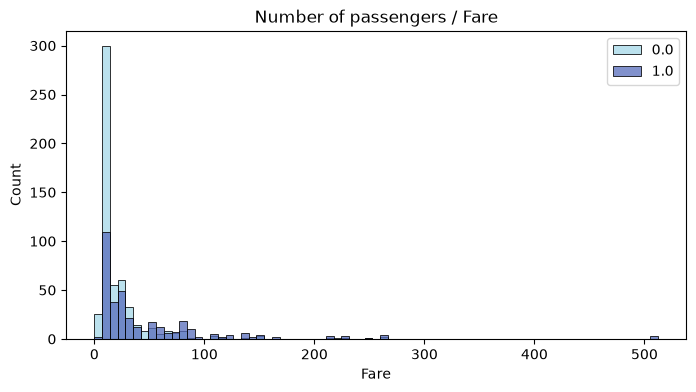

In [20]:
# Plot distribution pairs for Age and Fare using "Survived" as hue
for col in ["Age", "Fare"]:
    plot_distribution_pair(all_df, col, "Survived")